In [6]:
#Add your first + last names here:
member0 = "Dante Fisher" #Replace
member1 = ""
member2 = ""
print("Completed by:",member0, member1, member2)

Completed by: Dante Fisher  


# Introduction

Usually when we're given data, it's not in a form that we can use right away. Instead, we normally have to apply some preprocessing steps that transforms our data into something useful.

In this notebook, your goal is to use the variables stored in a dictionary to create new variables that can be used to model the time-course of signals acquired during a special type of MRI measurement called Arterial Spin Labeling (ASL).

During an ASL experiment, magnetization is applied to produce a measurable signal in the blood of the person being scanned. The labeled blood can then flow into the brain where imaging occurs. There are two main types of ASL: Pulsed ASL(PASL) and Pseudo-Continuous ASL (PCASL). These labeling schemes are visualized in the figure below:
<p style="text-align: center;">
<img src='ASL_labeling.png' width = '50%'>
</p>

**To begin, run the cell below.**

In [61]:
import discussion_functions as dsf #Loads in some functions that we'll use for this notebook
data_dict = dsf.load_dictionary()  #Uses the function that we loaded in called load_dictionary and assigns dictionary to data_dict
data_dict.keys()                   #Displays the keys for accessing items stored in data_dict

dict_keys(['PASL', 'PCASL'])

<div class="alert alert-success"><b>Task: </b>Use the keys above to access items stored in <code>data_dict</code>. What types of objects accessed with these keys?</div>

In [47]:
print(data_dict[...])
print(data_dict[...])

{'time': [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9], 'label_time': [0.6, 0.8, 1.0]}
{'time': [0, 0.2, 0.4, 0.6, 0.8, 1, 1.2, 1.4, 1.6, 1.8, 2, 2.2, 2.4, 2.6, 2.8, 3, 3.2, 3.4, 3.6, 3.8, 4, 4.2, 4.4, 4.6, 4.8, 5, 5.2, 5.4, 5.6, 5.8], 'label_time': [1.6, 1.8, 2.0]}


We can see that <code>data_dict</code> is a nested dictionary that separately stores variables related to PASL and PCASL experiments. In each case, there is a list variable that keeps track of experimental time and another list variable that contains several potential labeling times.

<div class="alert alert-success"><b>Task: </b>Use the proper indexing approach to extract the list variables representing <b>experimental time</b> and assign them to the variables <code>pasl_time</code> and <code>pcasl_time</code>.</div>

In [19]:
#Create time vectors
pasl_time = data_dict['PASL'][...] 
pcasl_time = ...
print(pasl_time)
print(pcasl_time)

[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9]
[0, 0.2, 0.4, 0.6, 0.8, 1, 1.2, 1.4, 1.6, 1.8, 2, 2.2, 2.4, 2.6, 2.8, 3, 3.2, 3.4, 3.6, 3.8, 4, 4.2, 4.4, 4.6, 4.8, 5, 5.2, 5.4, 5.6, 5.8]


Now that we have variables that represent experimental time, our next goal is to extract a variable that represents how long the blood was labeling in our experiment. Luckily the information is also stored in <code>my_dict</code>.

<div class="alert alert-success"><b>Task: </b>Use the proper indexing approach to extract the float variables representing <b>labeling times</b> and assign them to the variables <code>pasl_label</code> and <code>pcasl_label</code>. <i>Hint: Try using the value at index 1!</i></div>

In [63]:
#Extract label times
pasl_label = ...
pcasl_label = ...
print(f"PASL  labeling duration: {pasl_label} (s)")  #This is an f-string. 
print(f"PCASL labeling duration: {pcasl_label} (s)") #It's a convenient way use variable values in a string

PASL  labeling duration: 0.6 (s)
PCASL labeling duration: 1.6 (s)


### Creating the Remaining Variables with List Comprehension
Now that we've extracted our key variables from <code>my_dict</code>, we can use them to generate the variables we need for our ASL models. In the image below, we can see how time is broken up in our PASL and PCASL experiments:

<p style="text-align: center;">
<img src='ASL_timing.png' width='50%'>
</p>

In our experiments, time is broken up into a **labeling period** (<code>TI1</code> in PASL, <code>LD</code> in PCASL) and a **non-labeling period** (<code>TI</code> in PASL, <code>PLD</code> in PCASL). Note that for PASL <code>TI1</code> and <code>TI</code> start at the same time and overlap for the whole labeling period. In contrast, for PCASL <code>LD</code> occurs first and <code>PLD</code> only happens after the labeling period has finished. These observations are summarized in the table below:

| time-course variable| when time <= label_time | when time > label_time|
|---------------------|-------------------------|-----------------------|
| TI1 (PASL)          | <code>TI1[t] = time[t]</code>        | <code>TI1[t] = label_time</code>   |
| TI  (PASL)          | <code>TI[t] = time[t]</code>         | <code>TI[t] = time[t]</code>       |
| LD  (PCASL)         | <code>LD[t] = time[t]</code>         | <code>LD[t] = label_time</code>    |
| PLD (PCASL)         | <code>PLD[t] = 0</code>              | <code>PLD[t] = time[t] - label_time</code>|

Since we've already extracted time-related variables from our dictionary, we can create all of the variables in the preceding table using **list comprehensions** which allow us to create a new list from an existing list. The basic syntax is

<code> new_list = [new_t1 **if** old_t condition **else** new_t2 **for** old_t **in** old_list] </code>

To see this in action, run the cell below


In [60]:
old_list = [0, 1, 2, 3, 4, 5]
condition_label = 2
new_list = [t if t <= condition_label else 4 for t in old_list]
print(new_list)

[0, 1, 2, 4, 4, 4]


Let's use list comprehensions to complete the function below!

<div class="alert alert-success"><b>Task: </b>Complete the function below using list comprehensions and the table above. For some variables, there may be multiple ways to accomplish this task.</div>

In [64]:
def get_experiment_timings(time, label_time, mode='PASL'):

    if mode == 'PASL': #Replace this comment with a description of the code
        TI1 = [... if ... else ... for ... in ...]
        TI  = ...
        return TI1, TI
        
    elif mode == 'PCASL': #Replace this comment with a description of the code
        LD  = ...
        PLD = ...
        return LD, PLD

Once you've completed your function, **run the cell below to plot the resulting models!**

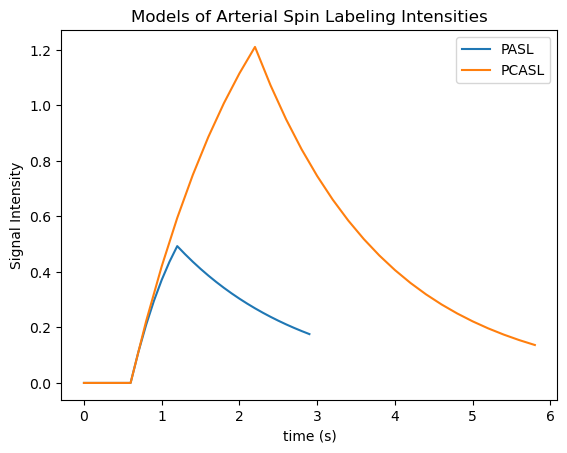

In [65]:
TI1, TI = get_experiment_timings(pasl_time, pasl_label, mode='PASL')
LD, PLD = get_experiment_timings(pcasl_time, pcasl_label, mode='PCASL')
dsf.plot_computed_models(pasl_time, TI1, TI,
                         pcasl_time, LD, PLD)